# LULC Semantic Segmentation from Sentinel-1

This notebook trains a deep learning model that turns **Sentinel-1 radar images** into a **land use / land cover (LULC) map** with 8 classes.

| | |
|---|---|
| **Input** | Sentinel-1 VV and VH backscatter only (radar works through clouds and at night) |
| **Output** | one class per 10 m pixel: Built-up, Cropland, Trees, Shrub & grass, Bare, Water, Wetland, Snow & ice |
| **Data** | 176 sites worldwide, year 2021, 12 monthly composites per site (see `Dataset/README.md`) |
| **Labels** | pixels where ESA WorldCover and Google Dynamic World agree |
| **Model** | U-Net, a convolutional neural network (CNN), with an ImageNet-pretrained ResNet-34 encoder |

**Roadmap**

1. Setup and settings
2. Load the data
3. Explore the data
4. Input features: from radar values to model inputs
5. PCA: a compact summary of the whole year
6. Datasets, augmentation and class balancing
7. The CNN model
8. Loss and metrics
9. Training
10. Results: training curves, test scores, confusion, seasonal effect, examples
11. Export for the prototype

**Baseline to beat** (commit `0811060`, previous dataset, no PCA): `three_month` reached test **OA 0.843, mIoU 0.559**.

**Kaggle setup:** add the dataset via *Add Input*, choose *GPU T4 x1*, and turn Internet on (pretrained weights).

## 1. Setup and settings

All the settings you might want to change are in the next code cell.

- `DEV = True` is the **quick experiment mode** (about 20 min). It trains fewer variants for at most 15 epochs and validates on 3 months instead of 12. Use it to try ideas.
- `DEV = False` is the **final run** for the report: all variants, up to 60 epochs, full validation.

In [1]:
DEV = True
# results go to Weights/<RUN_NAME>/; give every run a new name (an existing folder is never overwritten)
RUN_NAME = "Test_3"

ALL_VARIANTS = {
    "single_month":    dict(n_months=1, pca=False),
    "three_month":     dict(n_months=3, pca=False),
    "three_month_pca": dict(n_months=3, pca=True),
}

if DEV:
    RUN = ["three_month", "three_month_pca"]
    MAX_EPOCHS = 15
    VAL_MONTHS = [0, 4, 8]
else:
    RUN = list(ALL_VARIANTS)
    MAX_EPOCHS = 60
    VAL_MONTHS = list(range(12))

PATIENCE = 8
BATCH = 16
SAMPLES_PER_EPOCH = 2500
LEARNING_RATE = 3e-4
N_PCA = 6
CROP_JITTER = 128
NUM_WORKERS = 4
SEED = 42
VARIANTS = {name: ALL_VARIANTS[name] for name in RUN}
print("mode:", "DEV (quick)" if DEV else "FINAL", "| variants:", RUN, "| max epochs:", MAX_EPOCHS)

mode: DEV (quick) | variants: ['three_month', 'three_month_pca'] | max epochs: 15


In [2]:
import subprocess, sys
try:
    import rasterio
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rasterio"])
    import rasterio

import json, shutil, time, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| rasterio", rasterio.__version__)

DATA_DIRS = [Path("../input"), Path("Dataset"), Path("../Dataset")]
OUT = Path("Weights") / RUN_NAME
if OUT.exists() and any(OUT.iterdir()):
    OUT = OUT.with_name(f"{RUN_NAME}_{time.strftime('%Y%m%d_%H%M%S')}")
    print(f"Weights/{RUN_NAME} already has files, saving to {OUT} instead")


def find_data_root():
    for base in DATA_DIRS:
        if base.exists():
            for hit in base.rglob("train_patches.csv"):
                return hit.parent.parent
    raise FileNotFoundError("Dataset not found: attach the dataset with folders s1/, labels/, patches/")


DATA = find_data_root()
OUT.mkdir(parents=True, exist_ok=True)
print("data:", DATA, "| output:", OUT.resolve())

device: cuda Tesla T4
torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | rasterio 1.5.1
data: ../input/datasets/optimalbhandari/sentinel-1-2-0/Dataset | output: /kaggle/working/outputs


### Dataset constants

- **Radar values** are stored as uint8 codes to keep the dataset small: `dB = code * 0.2 - 35`. Code 0 means no data.
- **Labels:** 0 means *ignore* (the two label maps disagree). Classes 1-8 become indices 0-7 for training, and ignore becomes -1.

In [3]:
CLASS_NAMES = ["Built-up", "Cropland", "Trees", "Shrub & grass", "Bare / sparse",
               "Water", "Wetland & mangrove", "Snow & ice"]
CLASS_COLORS = ["#e31a1c", "#ffd92f", "#1a9850", "#a6d96a", "#bf812d", "#2c7fb8", "#41b6c4", "#f0f0f0"]
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
N_CLASSES = len(CLASS_NAMES)
IGNORE = -1
PATCH = 256
DB_MIN, DB_STEP = -35.0, 0.2

DB_LUT = (np.arange(256, dtype=np.float32) * DB_STEP + DB_MIN)
DB_LUT[0] = np.nan

CMAP = ListedColormap(["#000000"] + CLASS_COLORS)
LEGEND = [Patch(color=c, label=n) for n, c in zip(["ignore"] + CLASS_NAMES, ["#000000"] + CLASS_COLORS)]

## 2. Load the data

Each site is a 1024 x 1024 pixel tile (10.24 km) with 12 months x 2 polarisations. The patch index (`patches/<split>_patches.csv`) lists 256 x 256 windows with enough labels and valid radar data.

- **Train:** the **full tiles** stay in memory, so training can cut patches at random positions around the indexed windows (more variety than fixed patches).
- **Val and test:** the fixed indexed patches, so scores are comparable between runs.

The splits are **by site**: a test city or landscape is never seen during training.

In [4]:
SPLITS = ["train", "val", "test"]
index = {s: pd.read_csv(DATA / "patches" / f"{s}_patches.csv") for s in SPLITS}
for s in SPLITS:
    print(f"{s:5}: {len(index[s]):5} patches from {index[s].site.nunique():3} sites")


def read_site(site):
    with rasterio.open(DATA / "s1" / f"{site}.tif") as src:
        s1 = src.read().reshape(12, 2, src.height, src.width)
    with rasterio.open(DATA / "labels" / f"{site}.tif") as src:
        label = src.read(1).astype(np.int16) - 1
    return s1, label


TILE_X, TILE_Y = {}, {}
X, Y = {}, {}
t0 = time.time()
for s in SPLITS:
    df = index[s]
    if s != "train":
        X[s] = np.empty((len(df), 12, 2, PATCH, PATCH), dtype=np.uint8)
        Y[s] = np.empty((len(df), PATCH, PATCH), dtype=np.int16)
    for site, rows in df.groupby("site"):
        s1, label = read_site(site)
        if s == "train":
            TILE_X[site], TILE_Y[site] = s1, label
            continue
        for i, r, c in zip(rows.index, rows.row, rows.col):
            X[s][i] = s1[:, :, r:r + PATCH, c:c + PATCH]
            Y[s][i] = label[r:r + PATCH, c:c + PATCH]

TRAIN_ORIGINS = list(zip(index["train"].site, index["train"].row, index["train"].col))


def train_patch(i, dr=0, dc=0):
    site, r, c = TRAIN_ORIGINS[i]
    size = TILE_Y[site].shape[0]
    r = int(np.clip(r + dr, 0, size - PATCH))
    c = int(np.clip(c + dc, 0, size - PATCH))
    return TILE_X[site][:, :, r:r + PATCH, c:c + PATCH], TILE_Y[site][r:r + PATCH, c:c + PATCH]


Y["train"] = np.stack([train_patch(i)[1] for i in range(len(TRAIN_ORIGINS))])
gb = (sum(t.nbytes for t in TILE_X.values()) + sum(x.nbytes for x in X.values())) / 1e9
print(f"loaded in {time.time() - t0:.0f}s, {gb:.2f} GB of radar data in memory")

train:  1958 patches from 134 sites
val  :   327 patches from  22 sites
test :   302 patches from  20 sites
loaded in 233s, 4.36 GB of radar data in memory


## 3. Explore the data

**Class distribution.** The share of each class among labelled pixels. Built-up is the largest class because the prototype targets cities. Rare classes need extra care during training (section 6).

,train %,val %,test %
Built-up,30.8,35.0,54.2
Cropland,11.3,10.5,4.9
Trees,20.3,12.8,11.6
Shrub & grass,9.5,11.1,7.7
Bare / sparse,8.1,9.6,8.2
Water,8.0,13.7,5.0
Wetland & mangrove,5.4,4.7,6.2
Snow & ice,6.5,2.6,2.3


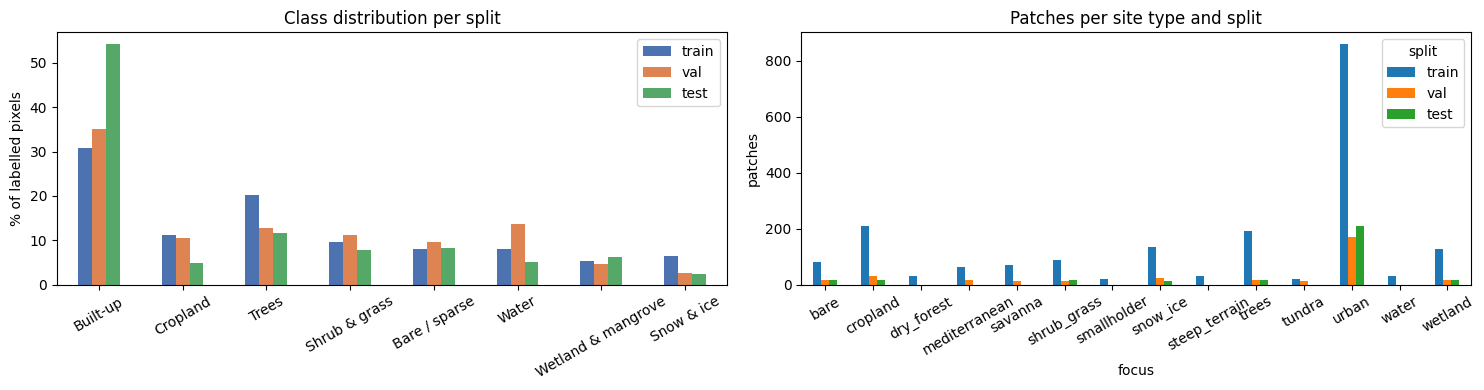

In [5]:
counts = {s: np.bincount(Y[s][Y[s] >= 0].ravel(), minlength=N_CLASSES) for s in SPLITS}
dist = pd.DataFrame({s: counts[s] / counts[s].sum() * 100 for s in SPLITS}, index=CLASS_NAMES).round(1)
display(dist.rename(columns=lambda s: f"{s} %"))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
dist.plot.bar(ax=axes[0], color=["#4c72b0", "#dd8452", "#55a868"])
axes[0].set_ylabel("% of labelled pixels")
axes[0].set_title("Class distribution per split")
axes[0].tick_params(axis="x", rotation=30)
all_patches = pd.concat([index[s].assign(split=s) for s in SPLITS], ignore_index=True)
pd.crosstab(all_patches.focus, all_patches.split)[SPLITS].plot.bar(ax=axes[1])
axes[1].set_ylabel("patches")
axes[1].set_title("Patches per site type and split")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**What the radar sees.** The false-colour images show R = VV, G = VH, B = VV - VH.

- Cities are bright: walls and the ground form corner reflectors (double bounce).
- Forests are green: leaves and branches scatter the signal in all directions, which raises VH (volume scattering).
- Water and smooth sand are dark: the surface reflects the signal away from the satellite.
- January vs July shows the **seasonal change**: snow, crop growth and wet soil all change the backscatter, while the annual label stays the same.

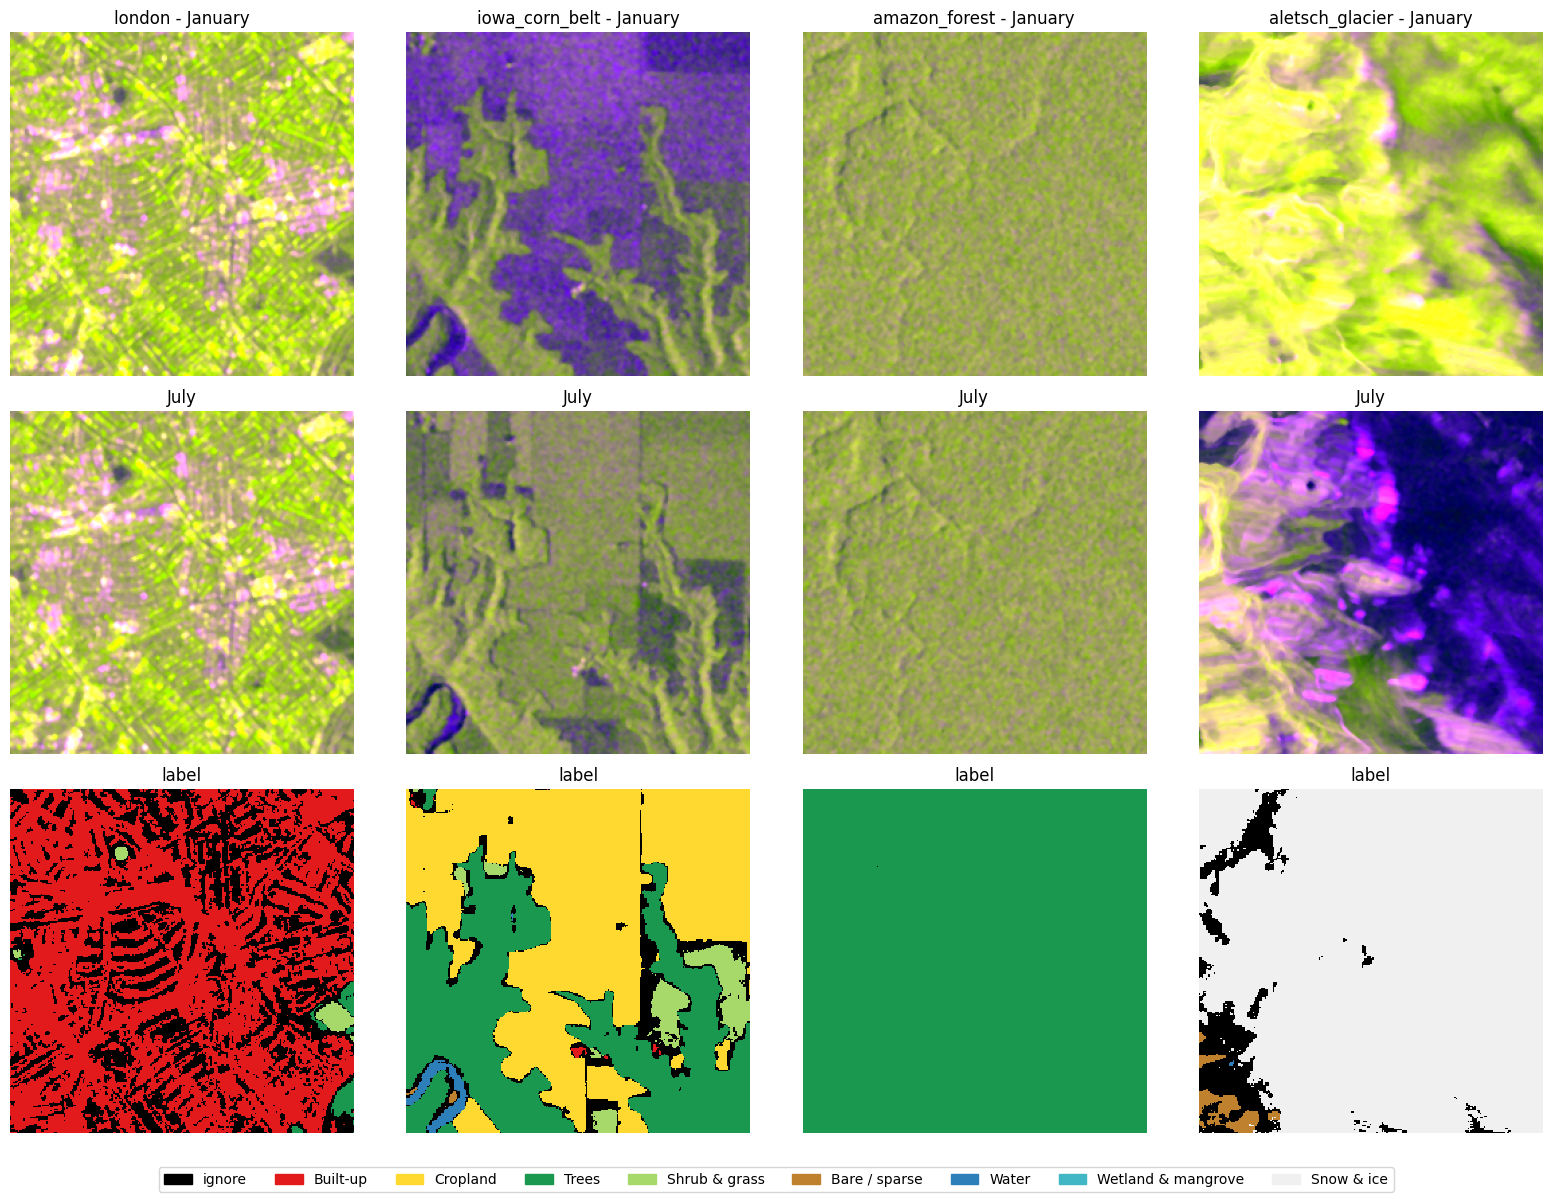

In [6]:
def false_colour(codes_2hw):
    vv, vh = DB_LUT[codes_2hw[0]], DB_LUT[codes_2hw[1]]
    rgb = np.stack([vv, vh, vv - vh], -1)
    for b, (lo, hi) in enumerate([(-20, 0), (-27, -7), (2, 15)]):
        rgb[..., b] = np.clip((rgb[..., b] - lo) / (hi - lo), 0, 1)
    return np.nan_to_num(rgb)


examples = [index["train"][index["train"].focus == f].index[0] for f in ["urban", "cropland", "trees", "snow_ice"]]
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for j, i in enumerate(examples):
    x, y = train_patch(i)
    axes[0, j].imshow(false_colour(x[0]))
    axes[0, j].set_title(f"{index['train'].site[i]} - January")
    axes[1, j].imshow(false_colour(x[6]))
    axes[1, j].set_title("July")
    axes[2, j].imshow(y + 1, cmap=CMAP, vmin=0, vmax=N_CLASSES, interpolation="nearest")
    axes[2, j].set_title("label")
for ax in axes.ravel():
    ax.axis("off")
fig.legend(handles=LEGEND, loc="lower center", ncol=9)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

## 4. Input features: from radar values to model inputs

Each month gives **three channels**:

| Channel | Meaning |
|---|---|
| VV (dB) | co-polarised backscatter: strong for buildings and rough surfaces |
| VH (dB) | cross-polarised backscatter: strong for vegetation (volume scattering) |
| VV - VH (dB) | the ratio of the two: separates vegetation from bare surfaces and buildings |

**Standardisation.** Each channel is shifted and scaled to mean 0 and standard deviation 1, using statistics from the **train split only** (no information leaks from val/test). Missing pixels become 0, which is the channel mean.

**Month window.** The `three_month` variants see the target month plus the two months before it. The window **wraps around the year**: January uses November, December and January. The previous run repeated January instead, so the January map had no history and scored worst. The label is annual, so using December 2021 as "the month before January" is valid for training. The prototype fetches the real previous months.

In [7]:
def standardise(f, mean, std):
    return np.nan_to_num((f - mean[None, :, None, None]) / std[None, :, None, None], nan=0.0)


def window_months(month, n_months):
    return [(month - j) % 12 for j in range(n_months - 1, -1, -1)]


def month_features(codes, months, shift_db=None):
    db = DB_LUT[codes[months]]
    if shift_db is not None:
        db = db + shift_db + np.random.normal(0, 0.5, db.shape).astype(np.float32)
    vv, vh = db[:, 0], db[:, 1]
    f = standardise(np.stack([vv, vh, vv - vh], 1), CH_MEAN, CH_STD)
    return f.reshape(-1, *codes.shape[-2:]).astype(np.float32)


sample = DB_LUT[np.stack([train_patch(i)[0][:, :, ::4, ::4] for i in range(0, len(TRAIN_ORIGINS), 4)])]
feats = np.stack([sample[:, :, 0], sample[:, :, 1], sample[:, :, 0] - sample[:, :, 1]], 0).reshape(3, -1)
CH_MEAN = np.nanmean(feats, axis=1).astype(np.float32)
CH_STD = np.nanstd(feats, axis=1).astype(np.float32)
del sample, feats
print("channel mean (VV, VH, VV-VH):", CH_MEAN.round(3))
print("channel std  (VV, VH, VV-VH):", CH_STD.round(3))

channel mean (VV, VH, VV-VH): [ -9.189 -16.591   7.402]
channel std  (VV, VH, VV-VH): [5.639 5.736 2.728]


## 5. PCA: a compact summary of the whole year

**What PCA does.** Principal Component Analysis finds the directions in which the data varies most, and re-expresses every sample along those directions. The first component captures the most variance, the second the most of what is left, and so on. Keeping only the first few components gives a **compact summary** with little information lost.

**How it is used here.** Every pixel has a 36-value time series: 12 months x 3 channels. Many of these values are redundant, because a forest looks similar in May and June. PCA compresses the 36 values into `N_PCA = 6` components:

- the first component is roughly the **average brightness** over the year (city vs forest vs water);
- the next ones describe **how the pixel changes over the year** (crops grow and are harvested, snow comes and goes, wetlands flood).

The `three_month_pca` variant adds these 6 components to its 9 monthly channels as **annual context**. This should help the classes that SAR confuses in a single month, such as cropland vs trees and water vs snow.

**Why not replace the inputs with PCA?** The model only has 3 channels per month, so there is nothing to reduce there. The CNN also learns its own, better features from the pixels. PCA helps as a cheap summary of the **time** dimension, not of the channels.

**Trade-off for the prototype.** The annual context is the same for all 12 monthly maps. This makes the maps more stable from month to month, which reduces fake change caused by seasons, but it can also hide real change that happens within the year.

The PCA is fitted on train pixels only.

variance explained by the first 6 components: 92.0%


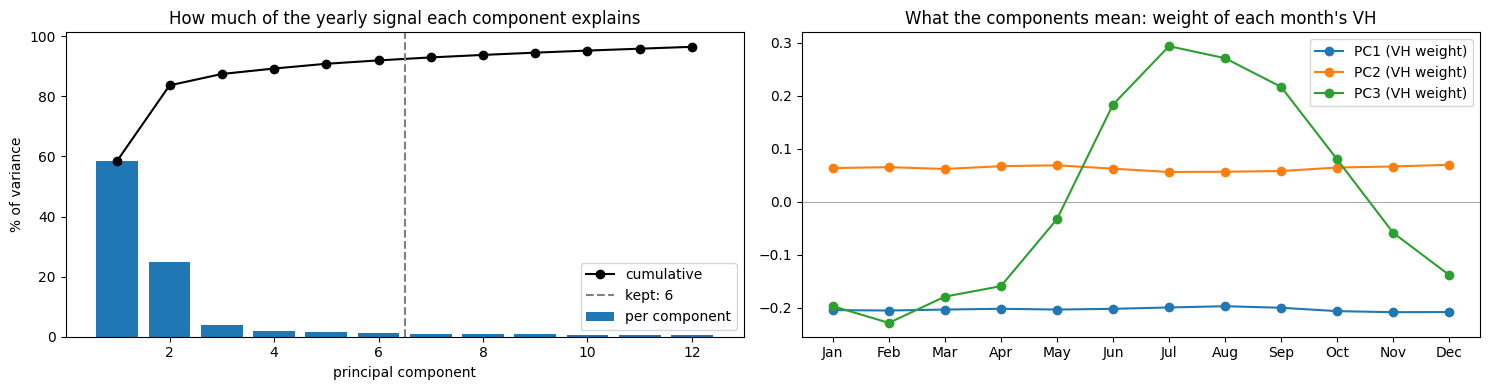

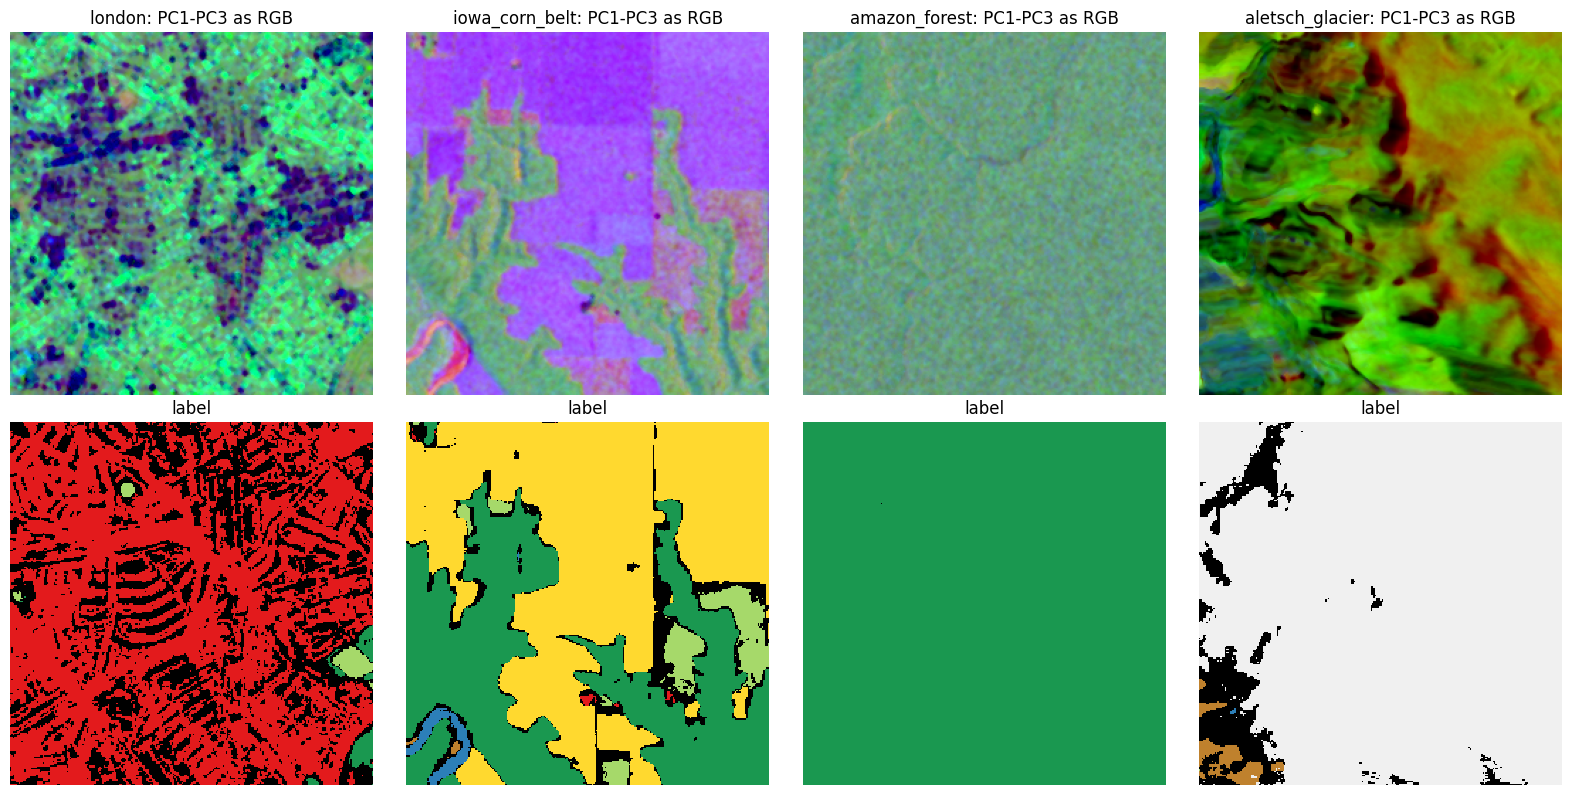

In [8]:
def annual_features(codes):
    return month_features(codes, list(range(12))).reshape(36, -1)


pixels = np.concatenate([annual_features(train_patch(i)[0][:, :, ::8, ::8])
                         for i in range(0, len(TRAIN_ORIGINS), 2)], axis=1)
PCA_MEAN = pixels.mean(1).astype(np.float32)
eigval, eigvec = np.linalg.eigh(np.cov(pixels - PCA_MEAN[:, None]))
order = np.argsort(eigval)[::-1]
eigval, eigvec = eigval[order], eigvec[:, order]
PCA_W = (eigvec[:, :N_PCA].T / np.sqrt(eigval[:N_PCA, None])).astype(np.float32)
explained = eigval / eigval.sum()
del pixels


def pca_features(codes):
    pcs = PCA_W @ (annual_features(codes) - PCA_MEAN[:, None])
    return pcs.reshape(N_PCA, *codes.shape[-2:]).astype(np.float32)


print("variance explained by the first", N_PCA, "components:", f"{explained[:N_PCA].sum() * 100:.1f}%")
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].bar(range(1, 13), explained[:12] * 100, label="per component")
axes[0].plot(range(1, 13), np.cumsum(explained[:12]) * 100, "o-", color="black", label="cumulative")
axes[0].axvline(N_PCA + 0.5, color="grey", ls="--", label=f"kept: {N_PCA}")
axes[0].set_xlabel("principal component")
axes[0].set_ylabel("% of variance")
axes[0].set_title("How much of the yearly signal each component explains")
axes[0].legend()
loadings = eigvec[:, :3].reshape(12, 3, 3)
for k in range(3):
    axes[1].plot(MONTH_NAMES, loadings[:, 1, k], marker="o", label=f"PC{k + 1} (VH weight)")
axes[1].axhline(0, color="grey", lw=0.5)
axes[1].set_title("What the components mean: weight of each month's VH")
axes[1].legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for j, i in enumerate(examples):
    x, y = train_patch(i)
    rgb = pca_features(x)[:3].transpose(1, 2, 0)
    axes[0, j].imshow(np.clip(rgb / 4 + 0.5, 0, 1))
    axes[0, j].set_title(f"{index['train'].site[i]}: PC1-PC3 as RGB")
    axes[1, j].imshow(y + 1, cmap=CMAP, vmin=0, vmax=N_CLASSES, interpolation="nearest")
    axes[1, j].set_title("label")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

**How to read this.** If a few components explain most of the variance, the yearly signal is very redundant and 6 numbers summarise it well. In the RGB images, areas with the same colour behave the same way over the year; compare them with the label map below.

## 6. Datasets, augmentation and class balancing

**One training item** = one patch, one random month, and the matching annual label. The model therefore learns to classify any single month, which is what the prototype needs (12 monthly maps).

**Augmentation** creates new, realistic variations of the training data. This fights **overfitting**: in the baseline, train mIoU reached 0.79 while val stayed at 0.47, so the model memorised the training sites.

| Augmentation | Why |
|---|---|
| random crop position (up to ±128 px around the indexed patch) | the model sees new pixel arrangements every epoch |
| flips and 90° rotations | land cover has no fixed orientation |
| random brightness shift (±1 dB) and noise (0.5 dB) | radar brightness varies with incidence angle, soil moisture and calibration between regions |

**Class balancing**

1. **Class weights in the loss:** `w = sqrt(median_freq / freq)`, so mistakes on rare classes cost more. The square root keeps rare classes from dominating.
2. **Patch sampler:** patches containing rare classes are drawn more often.

**Val and test** use fixed patches without augmentation. Test always uses all 12 months.

In [9]:
def model_input(codes, month, variant, shift_db=None):
    parts = [month_features(codes, window_months(month, variant["n_months"]), shift_db)]
    if variant["pca"]:
        parts.append(pca_features(codes))
    return np.concatenate(parts)


def input_channels(variant):
    return 3 * variant["n_months"] + (N_PCA if variant["pca"] else 0)


class TrainDataset(Dataset):
    def __init__(self, variant):
        self.variant = variant

    def __len__(self):
        return len(TRAIN_ORIGINS)

    def __getitem__(self, i):
        dr, dc = np.random.randint(-CROP_JITTER, CROP_JITTER + 1, 2)
        codes, label = train_patch(i, dr, dc)
        month = np.random.randint(12)
        x = model_input(codes, month, self.variant, shift_db=np.random.uniform(-1, 1))
        if np.random.rand() < 0.5:
            x, label = x[:, :, ::-1], label[:, ::-1]
        if np.random.rand() < 0.5:
            x, label = x[:, ::-1, :], label[::-1, :]
        rot = np.random.randint(4)
        x, label = np.rot90(x, rot, (1, 2)), np.rot90(label, rot)
        return torch.from_numpy(x.copy()), torch.from_numpy(label.astype(np.int64)), month


class EvalDataset(Dataset):
    def __init__(self, x, y, variant, months=range(12)):
        self.x, self.y, self.variant = x, y, variant
        self.items = [(i, m) for i in range(len(x)) for m in months]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, k):
        i, month = self.items[k]
        x = model_input(self.x[i], month, self.variant)
        return torch.from_numpy(x), torch.from_numpy(self.y[i].astype(np.int64)), month


def seed_worker(worker_id):
    np.random.seed(torch.initial_seed() % 2 ** 32)


freq = counts["train"] / counts["train"].sum()
CLASS_WEIGHTS = np.sqrt(np.median(freq) / np.clip(freq, 1e-6, None))
CLASS_WEIGHTS = (CLASS_WEIGHTS / CLASS_WEIGHTS.mean()).astype(np.float32)
display(pd.DataFrame({"train share %": (freq * 100).round(2), "loss weight": CLASS_WEIGHTS.round(2)},
                     index=CLASS_NAMES))

patch_frac = np.stack([np.bincount(y[y >= 0], minlength=N_CLASSES) / max((y >= 0).sum(), 1)
                       for y in Y["train"]])
PATCH_WEIGHTS = np.where(patch_frac >= 0.01, CLASS_WEIGHTS[None], 0).max(1)
print("patch sampling weight range:", PATCH_WEIGHTS.min().round(2), "-", PATCH_WEIGHTS.max().round(2))

,train share %,loss weight
Built-up,30.81,0.57
Cropland,11.32,0.93
Trees,20.32,0.70
Shrub & grass,9.52,1.02
Bare / sparse,8.08,1.10
Water,7.99,1.11
Wetland & mangrove,5.43,1.35
Snow & ice,6.53,1.23


patch sampling weight range: 0.57 - 1.35


## 7. The CNN model: U-Net with a ResNet-34 encoder

**Why a CNN.** A convolutional layer slides small learned filters (3 x 3 pixels) over the image. Early layers detect simple patterns such as edges and speckle texture. Deeper layers combine them into larger patterns such as street grids, field parcels or river banks. This is exactly what LULC mapping needs: the class of a pixel depends on its **neighbourhood**, not only on its own value.

**Encoder (ResNet-34, transfer learning).**
- The encoder shrinks the image step by step (1/2 ... 1/32 of the size) while learning more abstract features. At the deepest level, each feature sees about 2.5 km of context.
- It starts from weights pretrained on ImageNet photos. Edge and texture filters transfer to radar images, so training is faster and needs less data.
- The first layer is adapted to our channel count: its RGB filters are averaged and copied to every input channel, scaled by `3 / channels` to keep the same signal strength.

**Decoder (U-Net).**
- The decoder enlarges the features back to full size in 5 steps.
- **Skip connections** pass the sharp, high-resolution features from the encoder to the decoder at each step. This restores the 10 m detail needed for roads, rivers and field edges.
- A final 1 x 1 convolution gives 8 class scores per pixel.

```
input (C x 256 x 256)
  -> encoder: 128 -> 64 -> 32 -> 16 -> 8 px   (more channels, more context)
  -> decoder:   8 -> 16 -> 32 -> 64 -> 128 -> 256 px   (+ skip connections)
  -> 8 class scores per pixel
```

In [10]:
class UpBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch + skip_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))

    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        if skip is not None:
            x = torch.cat([x, skip], 1)
        return self.conv(x)


class UNetResNet34(nn.Module):
    def __init__(self, in_ch, n_classes, pretrained=True):
        super().__init__()
        try:
            enc = torchvision.models.resnet34(weights="IMAGENET1K_V1" if pretrained else None)
        except Exception as err:
            print("pretrained weights unavailable, using random init:", err)
            enc = torchvision.models.resnet34(weights=None)
        conv1 = nn.Conv2d(in_ch, 64, 7, stride=2, padding=3, bias=False)
        with torch.no_grad():
            conv1.weight.copy_(enc.conv1.weight.mean(1, keepdim=True).repeat(1, in_ch, 1, 1) * 3 / in_ch)
        self.stem = nn.Sequential(conv1, enc.bn1, enc.relu)
        self.pool = enc.maxpool
        self.enc1, self.enc2, self.enc3, self.enc4 = enc.layer1, enc.layer2, enc.layer3, enc.layer4
        self.dec4 = UpBlock(512, 256, 256)
        self.dec3 = UpBlock(256, 128, 128)
        self.dec2 = UpBlock(128, 64, 64)
        self.dec1 = UpBlock(64, 64, 64)
        self.dec0 = UpBlock(64, 0, 32)
        self.dropout = nn.Dropout2d(0.1)
        self.head = nn.Conv2d(32, n_classes, 1)

    def forward(self, x):
        s0 = self.stem(x)
        s1 = self.enc1(self.pool(s0))
        s2 = self.enc2(s1)
        s3 = self.enc3(s2)
        s4 = self.enc4(s3)
        d = self.dec4(s4, s3)
        d = self.dec3(d, s2)
        d = self.dec2(d, s1)
        d = self.dec1(d, s0)
        d = self.dec0(d)
        return self.head(self.dropout(d))


for name, variant in ALL_VARIANTS.items():
    print(f"{name:16} input channels: {input_channels(variant)}")
m = UNetResNet34(3, N_CLASSES, pretrained=False)
print(f"parameters: {sum(p.numel() for p in m.parameters()) / 1e6:.1f} M")
print("output shape:", tuple(m(torch.zeros(1, 3, PATCH, PATCH)).shape))
del m

single_month     input channels: 3
three_month      input channels: 9
three_month_pca  input channels: 15
parameters: 24.5 M
output shape: (1, 8, 256, 256)


## 8. Loss and metrics

**Loss = weighted sparse categorical cross-entropy + 0.5 x Dice**

- *Sparse categorical cross-entropy* compares the predicted class probabilities with the true class index of each pixel ("sparse" = integer labels, not one-hot vectors). It is PyTorch's `CrossEntropyLoss`, the same as Keras' `SparseCategoricalCrossentropy`. Ignored pixels (-1) are skipped, and the class weights from section 6 are applied.
- *Dice loss* directly rewards overlap between the predicted and true area of each class, regardless of how big the class is. It helps the rare classes.

**Metrics** (all from a confusion matrix over labelled pixels):

| Metric | Meaning | How to read it |
|---|---|---|
| **OA** (overall accuracy) | share of pixels classified correctly | inflated by the big built-up class |
| **IoU** per class | correct / (correct + false alarms + misses) | the strictest per-class score |
| **mIoU** | mean IoU over the 8 classes, each class counts equally | **the main score** |
| **F1** per class | balance of precision and recall; F1 = 2·IoU / (1 + IoU) | always higher than IoU |

In [11]:
class CEDiceLoss(nn.Module):
    def __init__(self, class_weights, dice_weight=0.5):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(weight=class_weights, ignore_index=IGNORE)
        self.dice_weight = dice_weight

    def forward(self, logits, target):
        ce = self.ce(logits, target)
        valid = (target != IGNORE).unsqueeze(1).float()
        probs = logits.float().softmax(1) * valid
        onehot = F.one_hot(target.clamp(min=0), N_CLASSES).permute(0, 3, 1, 2).float() * valid
        inter = (probs * onehot).sum((0, 2, 3))
        denom = (probs + onehot).sum((0, 2, 3))
        present = onehot.sum((0, 2, 3)) > 0
        dice = 1 - (2 * inter + 1) / (denom + 1)
        dice = dice[present].mean() if present.any() else ce * 0
        return ce + self.dice_weight * dice


def update_confusion(conf, logits, target):
    pred = logits.argmax(1)
    valid = target != IGNORE
    conf += torch.bincount(target[valid] * N_CLASSES + pred[valid],
                           minlength=N_CLASSES ** 2).reshape(N_CLASSES, N_CLASSES)
    return conf


def metrics_from_confusion(conf):
    conf = conf.double()
    tp = conf.diag()
    fp, fn = conf.sum(0) - tp, conf.sum(1) - tp
    iou = tp / (tp + fp + fn).clamp(min=1)
    f1 = 2 * tp / (2 * tp + fp + fn).clamp(min=1)
    present = conf.sum(1) > 0
    return {"OA": (tp.sum() / conf.sum()).item(),
            "mIoU": iou[present].mean().item(),
            "IoU": iou.cpu().numpy(), "F1": f1.cpu().numpy()}


criterion = CEDiceLoss(torch.tensor(CLASS_WEIGHTS, device=DEVICE))

## 9. Training

**How one variant is trained**

- **Optimiser:** AdamW (learning rate 3e-4, weight decay 1e-4) with mixed precision (faster on the GPU).
- **One epoch** = `SAMPLES_PER_EPOCH` patches drawn by the class-aware sampler, each with a random month and augmentation. The epoch length does not grow with the dataset, so epoch times stay comparable.
- **Learning-rate schedule:** the learning rate is halved when val mIoU has not improved for 3 epochs.
- **Early stopping:** training stops when val mIoU has not improved for `PATIENCE` epochs. The best checkpoint is restored and saved.

Each epoch prints the train and val scores. A `*` marks a new best val mIoU.

In [12]:
def evaluate(model, loader, per_month=False):
    model.eval()
    conf = torch.zeros(N_CLASSES, N_CLASSES, dtype=torch.long, device=DEVICE)
    month_conf = torch.zeros(12, N_CLASSES, N_CLASSES, dtype=torch.long, device=DEVICE) if per_month else None
    loss_sum, n = 0.0, 0
    with torch.no_grad(), torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
        for xb, yb, mb in loader:
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            logits = model(xb)
            loss_sum += criterion(logits, yb).item() * len(xb)
            n += len(xb)
            update_confusion(conf, logits, yb)
            if per_month:
                mb = mb.to(DEVICE)
                for m in mb.unique().tolist():
                    sel = mb == m
                    update_confusion(month_conf[m], logits[sel], yb[sel])
    out = metrics_from_confusion(conf)
    out["loss"], out["confusion"] = loss_sum / n, conf.cpu().numpy()
    if per_month:
        out["month_mIoU"] = [metrics_from_confusion(month_conf[m])["mIoU"] for m in range(12)]
    return out


def train_variant(name, variant):
    print(f"=== {name}: {input_channels(variant)} input channels ===")
    sampler = WeightedRandomSampler(torch.as_tensor(PATCH_WEIGHTS, dtype=torch.double),
                                    num_samples=SAMPLES_PER_EPOCH, replacement=True)
    train_dl = DataLoader(TrainDataset(variant), BATCH, sampler=sampler, num_workers=NUM_WORKERS,
                          pin_memory=True, drop_last=True, persistent_workers=NUM_WORKERS > 0,
                          worker_init_fn=seed_worker)
    val_dl = DataLoader(EvalDataset(X["val"], Y["val"], variant, VAL_MONTHS), 2 * BATCH,
                        num_workers=NUM_WORKERS, pin_memory=True)

    model = UNetResNet34(input_channels(variant), N_CLASSES).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)
    scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda")

    history, best, best_state, wait = [], -1.0, None, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        t0, loss_sum, n = time.time(), 0.0, 0
        conf = torch.zeros(N_CLASSES, N_CLASSES, dtype=torch.long, device=DEVICE)
        for xb, yb, _ in train_dl:
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
                logits = model(xb)
                loss = criterion(logits, yb)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            loss_sum += loss.item() * len(xb)
            n += len(xb)
            update_confusion(conf, logits.detach(), yb)
        train_m = metrics_from_confusion(conf)
        val_m = evaluate(model, val_dl)
        scheduler.step(val_m["mIoU"])
        history.append({"epoch": epoch, "train_loss": loss_sum / n, "val_loss": val_m["loss"],
                        "train_OA": train_m["OA"], "val_OA": val_m["OA"],
                        "train_mIoU": train_m["mIoU"], "val_mIoU": val_m["mIoU"],
                        "lr": optimizer.param_groups[0]["lr"]})
        improved = val_m["mIoU"] > best
        if improved:
            best, wait = val_m["mIoU"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save(best_state, OUT / f"{name}_best.pt")
        else:
            wait += 1
        print(f"epoch {epoch:2d} | train loss {loss_sum / n:.3f} mIoU {train_m['mIoU']:.3f} | "
              f"val loss {val_m['loss']:.3f} OA {val_m['OA']:.3f} mIoU {val_m['mIoU']:.3f} | "
              f"lr {optimizer.param_groups[0]['lr']:.1e} | {time.time() - t0:.0f}s{' *' if improved else ''}")
        if wait >= PATIENCE:
            print(f"early stopping: no val mIoU improvement for {PATIENCE} epochs")
            break

    model.load_state_dict(best_state)
    torch.save(best_state, OUT / f"{name}_best.pt")
    pd.DataFrame(history).to_csv(OUT / f"{name}_history.csv", index=False)
    print(f"best val mIoU {best:.3f}, weights saved to {OUT / f'{name}_best.pt'}")
    return model, pd.DataFrame(history)

In [13]:
models, histories = {}, {}
for name, variant in VARIANTS.items():
    models[name], histories[name] = train_variant(name, variant)

=== three_month: 9 input channels ===
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 258MB/s]


epoch  1 | train loss 1.880 mIoU 0.315 | val loss 1.571 OA 0.661 mIoU 0.359 | lr 3.0e-04 | 34s *
epoch  2 | train loss 1.596 mIoU 0.394 | val loss 1.467 OA 0.672 mIoU 0.385 | lr 3.0e-04 | 31s *
epoch  3 | train loss 1.498 mIoU 0.431 | val loss 1.347 OA 0.704 mIoU 0.413 | lr 3.0e-04 | 31s *
epoch  4 | train loss 1.401 mIoU 0.460 | val loss 1.430 OA 0.640 mIoU 0.375 | lr 3.0e-04 | 32s
epoch  5 | train loss 1.336 mIoU 0.485 | val loss 1.298 OA 0.688 mIoU 0.427 | lr 3.0e-04 | 32s *
epoch  6 | train loss 1.305 mIoU 0.485 | val loss 1.292 OA 0.696 mIoU 0.436 | lr 3.0e-04 | 32s *
epoch  7 | train loss 1.219 mIoU 0.515 | val loss 1.219 OA 0.729 mIoU 0.458 | lr 3.0e-04 | 32s *
epoch  8 | train loss 1.185 mIoU 0.529 | val loss 1.255 OA 0.696 mIoU 0.417 | lr 3.0e-04 | 32s
epoch  9 | train loss 1.161 mIoU 0.532 | val loss 1.280 OA 0.697 mIoU 0.424 | lr 3.0e-04 | 32s
epoch 10 | train loss 1.086 mIoU 0.560 | val loss 1.108 OA 0.764 mIoU 0.518 | lr 3.0e-04 | 32s *
epoch 11 | train loss 1.054 mIoU 0.5

## 10. Results

### 10.1 Training curves

**How to read them**

- **Train and val going down / up together:** the model is learning patterns that generalise.
- **Train keeps improving while val stalls:** overfitting. The gap between the two curves measures it.
- **Val jumping up and down** by a few points between epochs is normal with only ~19 val sites. Differences smaller than about 0.02 mIoU between experiments are noise.
- The dashed line marks the best epoch, whose weights are kept (early stopping).

three_month: best epoch 14, train-val mIoU gap at best epoch 0.054 (baseline: 0.31)
three_month_pca: best epoch 14, train-val mIoU gap at best epoch 0.127 (baseline: 0.31)


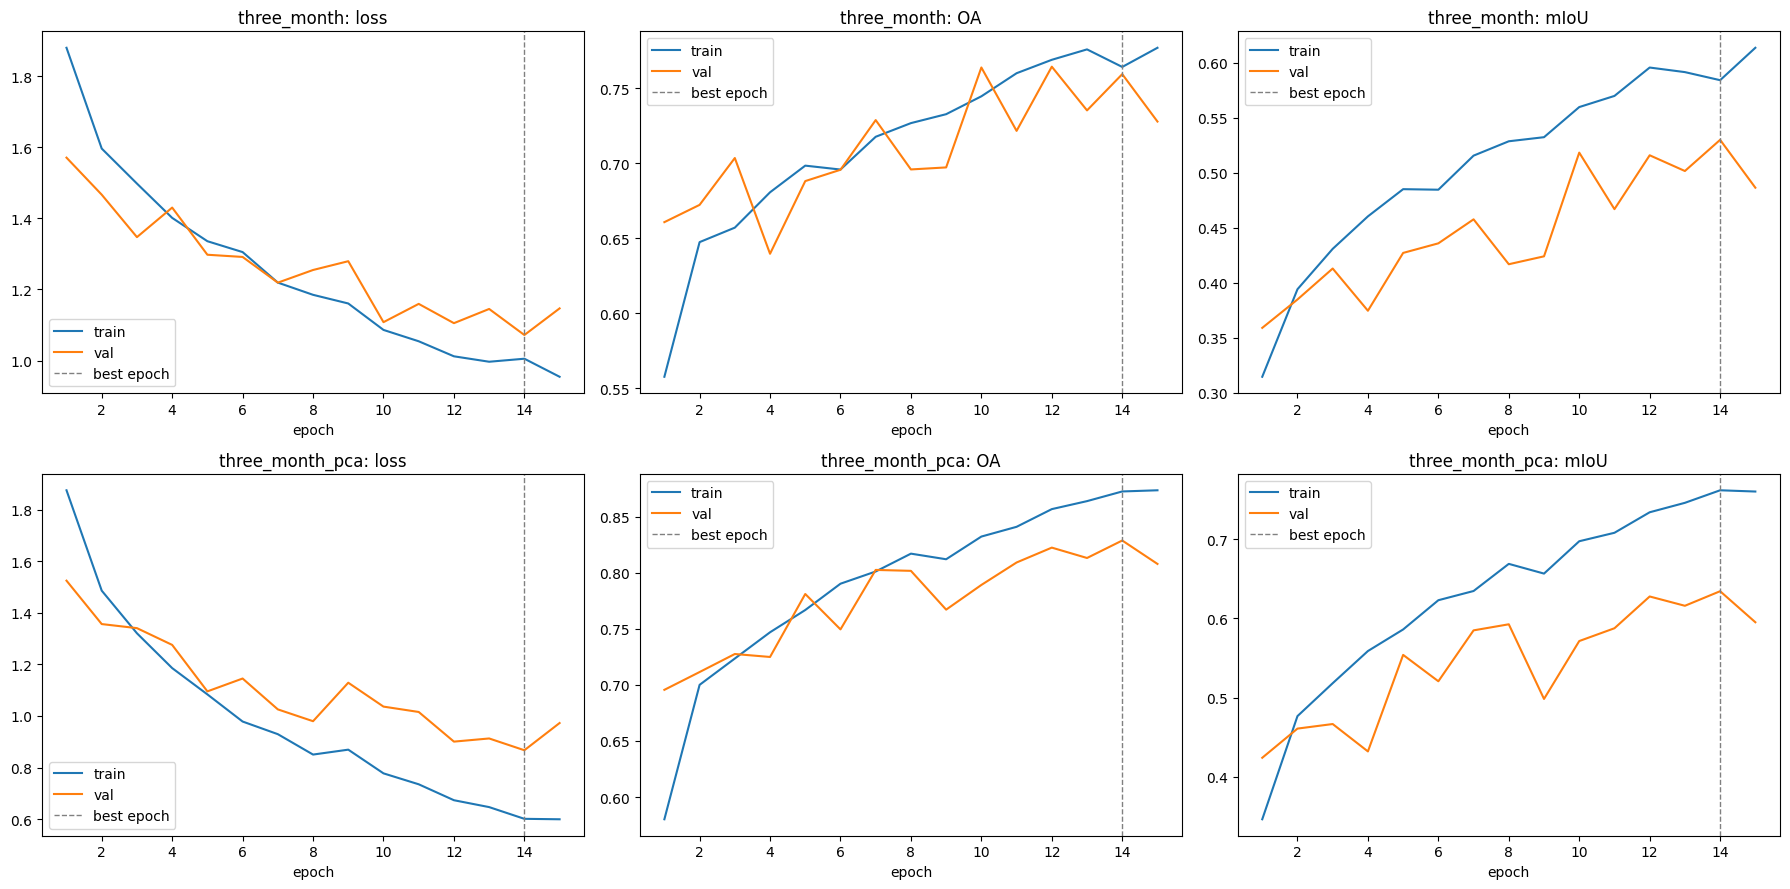

In [14]:
fig, axes = plt.subplots(len(histories), 3, figsize=(18, 4.5 * len(histories)), squeeze=False)
for row, (name, h) in enumerate(histories.items()):
    best_epoch = h.epoch[h.val_mIoU.idxmax()]
    for ax, metric in zip(axes[row], ["loss", "OA", "mIoU"]):
        ax.plot(h.epoch, h[f"train_{metric}"], label="train")
        ax.plot(h.epoch, h[f"val_{metric}"], label="val")
        ax.axvline(best_epoch, color="grey", ls="--", lw=1, label="best epoch")
        ax.set_title(f"{name}: {metric}")
        ax.set_xlabel("epoch")
        ax.legend()
    gap = h.train_mIoU[h.val_mIoU.idxmax()] - h.val_mIoU.max()
    print(f"{name}: best epoch {best_epoch}, train-val mIoU gap at best epoch {gap:.3f} (baseline: 0.31)")
plt.tight_layout()
plt.savefig(OUT / "training_curves.png", dpi=120)
plt.show()

### 10.2 Test scores

The test set has 20 sites that were never used for training or model selection. Every test patch is evaluated with **all 12 months**. The test sites are the same as in the baseline run. The seasonal snow label fix added a few labelled test pixels (mainly Anchorage), so the comparison with the baseline is close but not exact.

In [15]:
BASELINE = {"OA": 0.8427, "mIoU": 0.5593}
results = {}
for name, variant in VARIANTS.items():
    test_dl = DataLoader(EvalDataset(X["test"], Y["test"], variant), 2 * BATCH,
                         num_workers=NUM_WORKERS, pin_memory=True)
    results[name] = evaluate(models[name], test_dl, per_month=True)

comparison = pd.DataFrame({name: {"OA": r["OA"], "mIoU": r["mIoU"],
                                  "mIoU vs baseline": r["mIoU"] - BASELINE["mIoU"],
                                  "best val mIoU": histories[name].val_mIoU.max(),
                                  "epochs": len(histories[name])}
                           for name, r in results.items()}).T
display(comparison.round(4))

per_class = pd.concat({name: pd.DataFrame({"IoU": r["IoU"], "F1": r["F1"]}, index=CLASS_NAMES)
                       for name, r in results.items()}, axis=1)
display(per_class.round(3))

BEST = comparison.mIoU.idxmax()
print("best variant on test:", BEST)
json.dump({name: {"OA": r["OA"], "mIoU": r["mIoU"],
                  "IoU": dict(zip(CLASS_NAMES, r["IoU"].round(4).tolist())),
                  "F1": dict(zip(CLASS_NAMES, r["F1"].round(4).tolist())),
                  "month_mIoU": [round(v, 4) for v in r["month_mIoU"]]}
           for name, r in results.items()}, open(OUT / "test_metrics.json", "w"), indent=2)

,OA,mIoU,mIoU vs baseline,best val mIoU,epochs
three_month,0.8225,0.5379,-0.0214,0.5299,15.0
three_month_pca,0.8127,0.4851,-0.0742,0.6343,15.0


three_month        three_month_pca       
                           IoU     F1             IoU     F1
Built-up                 0.942  0.970           0.941  0.970
Cropland                 0.556  0.715           0.361  0.530
Trees                    0.478  0.646           0.614  0.761
Shrub & grass            0.152  0.264           0.273  0.429
Bare / sparse            0.739  0.850           0.651  0.788
Water                    0.443  0.614           0.468  0.638
Wetland & mangrove       0.611  0.759           0.155  0.269
Snow & ice               0.383  0.554           0.418  0.590

best variant on test: three_month


### 10.3 Confusion matrix

Each **row** is a true class and each **column** a predicted class. The rows sum to 1, so the diagonal is the share of each class that was found (recall). Large off-diagonal values show which classes the radar confuses, for example trees vs cropland (both scatter in the vegetation volume) or water vs snow (both can be dark and smooth).

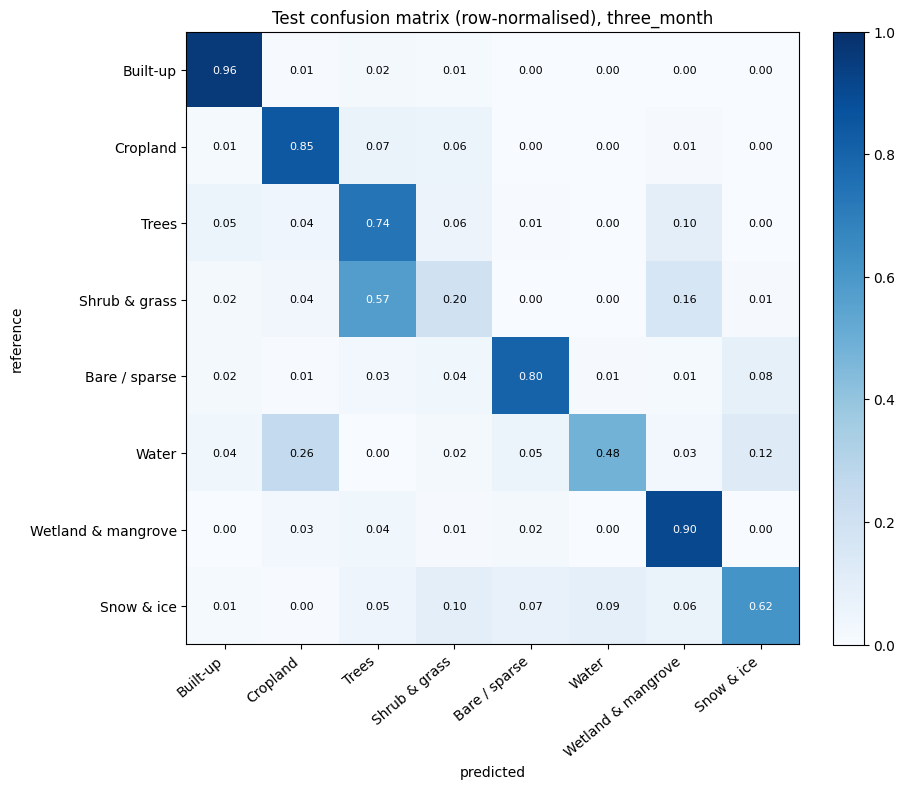

In [16]:
conf = results[BEST]["confusion"].astype(np.float64)
conf_norm = conf / conf.sum(1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(conf_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        ax.text(j, i, f"{conf_norm[i, j]:.2f}", ha="center", va="center",
                color="white" if conf_norm[i, j] > 0.5 else "black", fontsize=8)
ax.set_xticks(range(N_CLASSES), CLASS_NAMES, rotation=40, ha="right")
ax.set_yticks(range(N_CLASSES), CLASS_NAMES)
ax.set_xlabel("predicted")
ax.set_ylabel("reference")
ax.set_title(f"Test confusion matrix (row-normalised), {BEST}")
plt.colorbar(im, fraction=0.046)
plt.tight_layout()
plt.savefig(OUT / "confusion_matrix.png", dpi=120)
plt.show()

### 10.4 Scores per region, site type and month

- **Per region** shows how well the model transfers to different parts of the world.
- **Per site type** groups the test sites by their dominant landscape. Read the OA column here: inside one site type the rare classes have few pixels, which makes mIoU unstable.
- **Per month** shows the **seasonal effect**. The label is the same all year, so a drop in some months means the radar signal changed (snow, frozen or wet soil, bare fields after harvest). In the prototype, such drops appear as fake land-cover change.

,patches,OA,mIoU
region,,,
africa,49,0.599,0.289
asia,109,0.856,0.506
europe,32,0.951,0.451
n_america,64,0.783,0.406
oceania,16,0.966,0.399
s_america,32,0.943,0.371


,patches,OA,mIoU
focus,,,
bare,16,1.000,1.000
cropland,17,0.864,0.316
shrub_grass,16,0.155,0.032
snow_ice,13,0.430,0.149
trees,16,0.711,0.182
urban,208,0.889,0.335
wetland,16,0.892,0.216


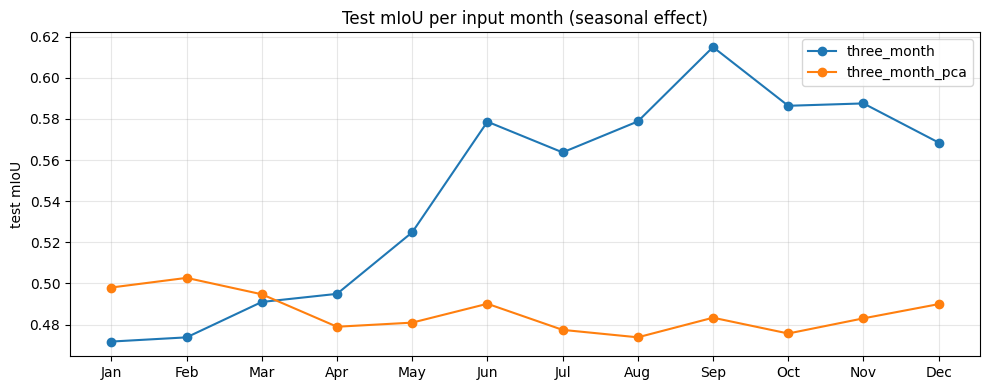

In [17]:
def group_scores(model, variant, column):
    rows = []
    for group, df in index["test"].groupby(column):
        ids = df.index.to_numpy()
        dl = DataLoader(EvalDataset(X["test"][ids], Y["test"][ids], variant), 2 * BATCH, num_workers=NUM_WORKERS)
        r = evaluate(model, dl)
        rows.append({column: group, "patches": len(ids), "OA": r["OA"], "mIoU": r["mIoU"]})
    return pd.DataFrame(rows).set_index(column).round(3)


display(group_scores(models[BEST], VARIANTS[BEST], "region"))
display(group_scores(models[BEST], VARIANTS[BEST], "focus"))

plt.figure(figsize=(10, 4))
for name, r in results.items():
    plt.plot(MONTH_NAMES, r["month_mIoU"], marker="o", label=name)
plt.ylabel("test mIoU")
plt.title("Test mIoU per input month (seasonal effect)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "month_miou.png", dpi=120)
plt.show()

### 10.5 Example predictions on unseen test sites

One test patch per site type, predicted from the July composite. Black pixels in the reference are *ignore* (the label maps disagree); the model still predicts them.

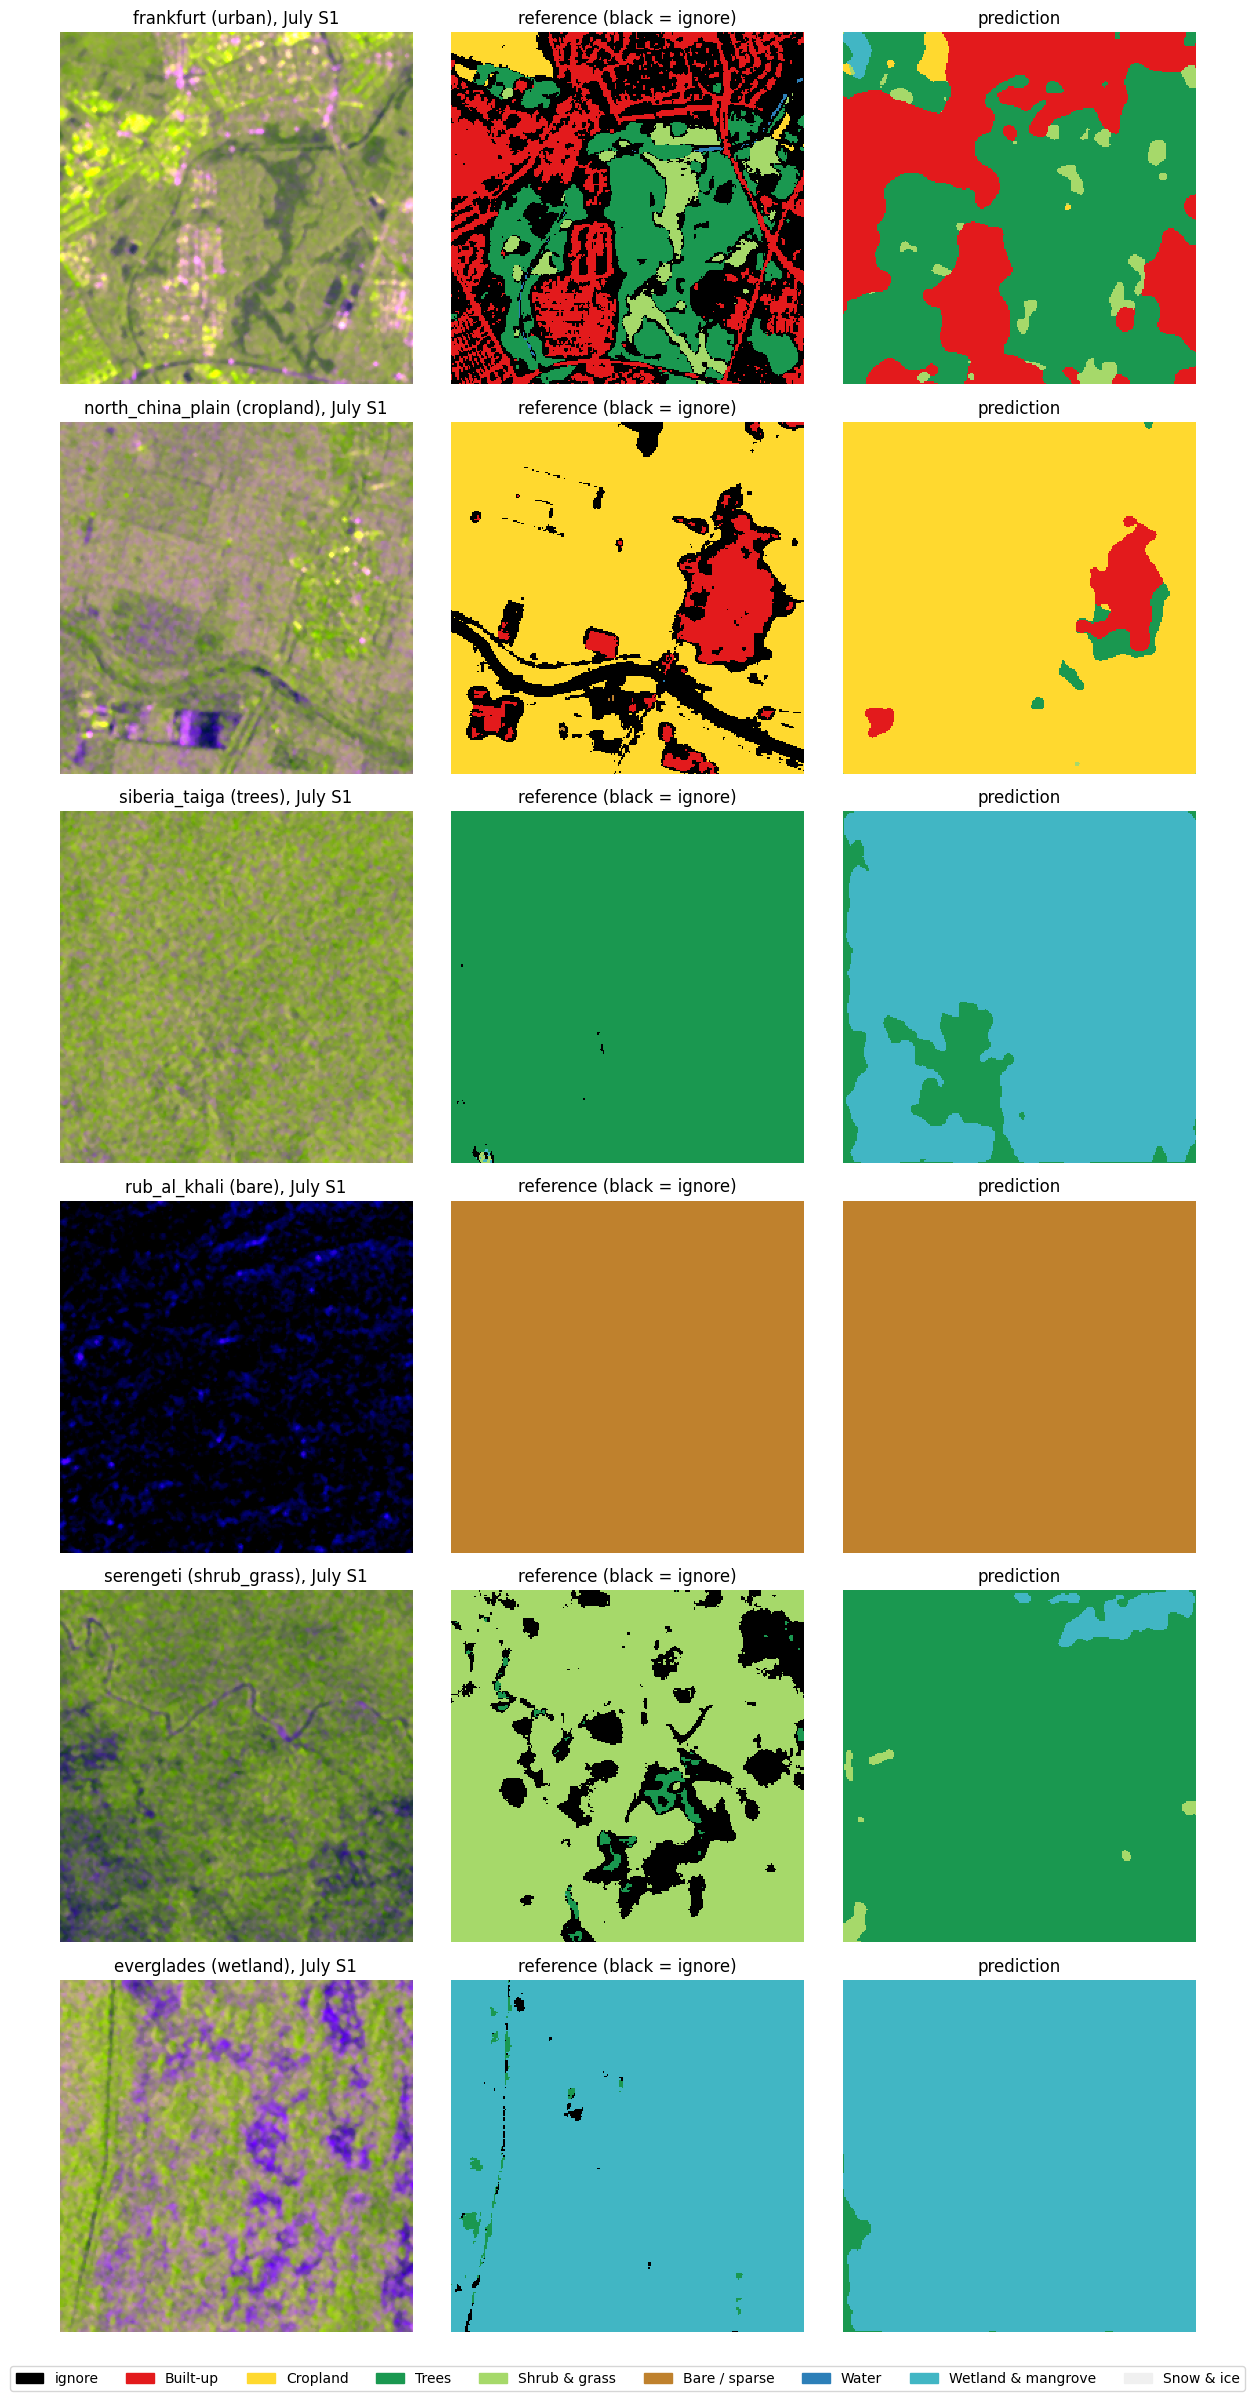

In [18]:
model = models[BEST].eval()
picks = [index["test"][index["test"].focus == f].index[0] for f in index["test"].focus.unique()][:6]
fig, axes = plt.subplots(len(picks), 3, figsize=(12, 4 * len(picks)))
for row, i in enumerate(picks):
    month = 6
    x = model_input(X["test"][i], month, VARIANTS[BEST])
    with torch.no_grad():
        pred = model(torch.from_numpy(x)[None].to(DEVICE)).argmax(1)[0].cpu().numpy()
    axes[row, 0].imshow(false_colour(X["test"][i, month]))
    axes[row, 0].set_title(f"{index['test'].site[i]} ({index['test'].focus[i]}), July S1")
    axes[row, 1].imshow(Y["test"][i] + 1, cmap=CMAP, vmin=0, vmax=N_CLASSES, interpolation="nearest")
    axes[row, 1].set_title("reference (black = ignore)")
    axes[row, 2].imshow(pred + 1, cmap=CMAP, vmin=0, vmax=N_CLASSES, interpolation="nearest")
    axes[row, 2].set_title("prediction")
for ax in axes.ravel():
    ax.axis("off")
fig.legend(handles=LEGEND, loc="lower center", ncol=9)
plt.tight_layout(rect=(0, 0.02, 1, 1))
plt.savefig(OUT / "example_predictions.png", dpi=110)
plt.show()

## 11. Export for the prototype

The best model's weights are saved with everything the prototype needs to reproduce the preprocessing exactly:
- the channels, the number of months and the month-window rule;
- the normalisation statistics;
- the PCA mean and projection matrix (used only if the best variant has PCA input);
- the uint8 decoding, class names and colours.

In [19]:
model_card = {
    "variant": BEST,
    "n_months": VARIANTS[BEST]["n_months"],
    "pca": VARIANTS[BEST]["pca"],
    "in_channels": input_channels(VARIANTS[BEST]),
    "channels_per_month": ["VV_dB", "VH_dB", "VV_minus_VH_dB"],
    "month_window": "target month and the previous n_months-1 months, oldest first",
    "pca_input": "36 standardised values per pixel (Jan..Dec x VV, VH, VV-VH), ordered by calendar month; "
                 "components = pca_weights @ (values - pca_mean)",
    "channel_mean": CH_MEAN.tolist(),
    "channel_std": CH_STD.tolist(),
    "pca_mean": PCA_MEAN.tolist(),
    "pca_weights": PCA_W.tolist(),
    "nan_fill_after_standardisation": 0.0,
    "db_decoding": {"db_min": DB_MIN, "db_step": DB_STEP, "nodata_code": 0},
    "class_names": CLASS_NAMES,
    "class_colors": CLASS_COLORS,
    "patch_size": PATCH,
    "architecture": "UNetResNet34 (this notebook)",
    "weights": f"{BEST}_best.pt",
    "test_OA": results[BEST]["OA"],
    "test_mIoU": results[BEST]["mIoU"],
}
json.dump(model_card, open(OUT / "model_card.json", "w"), indent=2)
print({k: v for k, v in model_card.items() if k not in ("pca_mean", "pca_weights")})
print(sorted(p.name for p in OUT.iterdir()))

{'variant': 'three_month', 'n_months': 3, 'pca': False, 'in_channels': 9, 'channels_per_month': ['VV_dB', 'VH_dB', 'VV_minus_VH_dB'], 'month_window': 'target month and the previous n_months-1 months, oldest first', 'pca_input': '36 standardised values per pixel (Jan..Dec x VV, VH, VV-VH), ordered by calendar month; components = pca_weights @ (values - pca_mean)', 'channel_mean': [-9.189177513122559, -16.59076499938965, 7.4015703201293945], 'channel_std': [5.639369487762451, 5.7359724044799805, 2.7277612686157227], 'nan_fill_after_standardisation': 0.0, 'db_decoding': {'db_min': -35.0, 'db_step': 0.2, 'nodata_code': 0}, 'class_names': ['Built-up', 'Cropland', 'Trees', 'Shrub & grass', 'Bare / sparse', 'Water', 'Wetland & mangrove', 'Snow & ice'], 'class_colors': ['#e31a1c', '#ffd92f', '#1a9850', '#a6d96a', '#bf812d', '#2c7fb8', '#41b6c4', '#f0f0f0'], 'patch_size': 256, 'architecture': 'UNetResNet34 (this notebook)', 'weights': 'three_month_best.pt', 'test_OA': 0.8225343430972982, 'test_

## 12. Save the run

Everything above is already written to `Weights/<RUN_NAME>/`. The best weights are saved at every improvement, so a crash keeps the last best. This cell saves the final weights and histories once more and zips the folder, so the whole run is one download from Kaggle's **Output** tab. Only committed runs (**Save Version → Save & Run All**) keep their output.

In [ ]:
for name in models:
    torch.save(models[name].state_dict(), OUT / f"{name}_best.pt")
    histories[name].to_csv(OUT / f"{name}_history.csv", index=False)
archive = shutil.make_archive(str(OUT), "zip", OUT)
print("saved:", sorted(p.name for p in OUT.iterdir()))
print("archive:", archive)
